# 02 – Đặc trưng dự báo ngày kế tiếp

**Mục tiêu.** Xây dựng các đặc trưng lag, rolling và lịch cho từng chuỗi `region_id × aoi_type`, kiểm tra rằng chúng không dùng thông tin của ngày dự báo hay các ngày sau, và xác định các ô đủ điều kiện để huấn luyện và chấm điểm.

**Nguyên tắc.** Nhu cầu quan sát được dịch lùi trước khi tính rolling, nên đặc trưng của ngày $t$ chỉ dùng thông tin đến ngày $t-1$. Ngày không có bản ghi trên toàn thành phố là chưa biết: giữ NaN trong lag và rolling, không dùng làm nhãn, không thay bằng 0. Đặc trưng chỉ được tính trong cửa sổ thực nghiệm, không lấy lịch sử trước cửa sổ.

| Nhóm | Đặc trưng |
|---|---|
| Độ trễ | `lag_1`, `lag_7`, `lag_14` |
| Rolling (dịch một ngày) | `rolling_mean_7`, `rolling_mean_14`, `rolling_std_7`, `rolling_std_14` |
| Lịch | `day_of_week`, `is_weekend`, `day_of_month`, `month` (thứ trong tuần dựa trên năm quy ước 2022) |
| Không gian | `region_id`, `aoi_type` |

In [1]:
import sys, json
from pathlib import Path
root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(root))  # repository root, so that `src` is importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src import config

from src.data_loader import loadDemandPanel
from src.features import buildScenarioFeatures, evaluationCells
from src.visualization import saveFigure

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
dateCol = config.DEMAND_DATE_COLUMN

panel = loadDemandPanel()
window = json.loads(config.STABLE_PERIOD_FILE.read_text())
bounds = window["splits"]["primary_stable_period"]
data = buildScenarioFeatures(panel, bounds)
print("scenario window:", bounds["train"][0], "->", bounds["test"][1], "| rows:", len(data), "| series:", data.series_id.nunique())
display(data.loc[data.series_id == "r53_t1", [dateCol, "split", "demand", "lag_1", "lag_7", "lag_14", "rolling_mean_7",
                                              "rolling_std_7", "rolling_mean_14", "history_ready"]].iloc[[0, 1, 7, 13, 14, 15, 60, 61]])

scenario window: 2022-06-27 -> 2022-10-02 | rows: 4018 | series: 41


,ds_date,split,demand,lag_1,lag_7,lag_14,rolling_mean_7,rolling_std_7,rolling_mean_14,history_ready
5146,2022-06-27,train,38,NaN,NaN,NaN,NaN,NaN,NaN,False
5147,2022-06-28,train,39,38.0,NaN,NaN,NaN,NaN,NaN,False
5153,2022-07-04,train,48,53.0,38.0,NaN,47.714286,7.977008,NaN,False
5159,2022-07-10,train,44,50.0,53.0,NaN,48.714286,2.602981,NaN,False
5160,2022-07-11,train,24,44.0,48.0,38.0,47.428571,2.381905,47.571429,True
5161,2022-07-12,train,29,24.0,45.0,39.0,44.000000,8.502101,46.571429,True
5206,2022-08-26,validation,71,53.0,68.0,81.0,66.571429,6.521550,66.142857,True
5207,2022-08-27,validation,68,71.0,68.0,64.0,67.000000,6.697548,65.428571,True


## 1. Các split và số ngày đủ điều kiện

In [2]:
rows = []
for split in ("train", "validation", "test"):
    sub = data[data.split == split]
    ready = sub[sub.history_ready & sub.city_observed]
    rows.append({"split": split, "start": bounds[split][0], "end": bounds[split][1], "days": sub[dateCol].nunique(),
                 "rows": len(sub), "eligible days": ready[dateCol].nunique(), "eligible rows": len(ready),
                 "eligible orders": int(ready.demand.sum())})
display(pd.DataFrame(rows).set_index("split"))
print("unobserved city days inside the window:", sorted(data.loc[~data.city_observed, dateCol].dt.strftime("%Y-%m-%d").unique()))
firstReady = data.loc[data.history_ready, dateCol].min()
print("first day with a full 14-day history:", firstReady.date(), "| warm-up days kept as history:", config.WARMUP_DAYS)

,start,end,days,rows,eligible days,eligible rows,eligible orders
split,,,,,,,
train,2022-06-27,2022-08-23,58,2378,44,1804,10835
validation,2022-08-24,2022-09-12,20,820,20,820,5300
test,2022-09-13,2022-10-02,20,820,20,820,4732


unobserved city days inside the window: []
first day with a full 14-day history: 2022-07-11 | warm-up days kept as history: 14


## 2. Kiểm tra không rò rỉ thông tin

In [3]:
# (a) Perturb the target from a cutoff day on: every feature up to the cutoff must stay identical.
cutoff = pd.Timestamp(bounds["validation"][0]) + pd.Timedelta(days=6)
changed = panel.copy()
changed.loc[changed[dateCol] >= cutoff, "demand"] += 99999
other = buildScenarioFeatures(changed, bounds)
featureCols = [c for c in data.columns if c.startswith(("lag_", "rolling_"))]
before = data[dateCol] <= cutoff
pd.testing.assert_frame_equal(data.loc[before, featureCols].reset_index(drop=True), other.loc[before, featureCols].reset_index(drop=True))
print(f"features on or before {cutoff.date()} are unchanged when the target from {cutoff.date()} on is altered: PASS")

# (b) The first rolling value of a series equals the mean of the previous days only.
one = data[data.series_id == "r53_t1"].reset_index(drop=True)
i = int(one.index[one.history_ready][0])
assert np.isclose(one.loc[i, "rolling_mean_14"], one.loc[i - 14:i - 1, "observed_demand"].mean())
assert np.isclose(one.loc[i, "lag_7"], one.loc[i - 7, "observed_demand"])
print("rolling_mean_14 and lag_7 are computed from days before t only: PASS")

# (c) A day without city records is unknown, never zero.
unknown = data.loc[~data.city_observed, dateCol]
print("unknown days in features:", int(data["observed_demand"].isna().sum() / data.series_id.nunique()),
      "| lag_1 of the day after an unknown day is NaN:", bool(data.loc[data[dateCol].isin(unknown + pd.Timedelta(days=1)), "lag_1"].isna().all()))

# (d) The saved feature table equals the one rebuilt here.
saved = pd.read_parquet(config.featuresFile("primary_stable_period"))
pd.testing.assert_frame_equal(saved[featureCols].reset_index(drop=True), data[featureCols].reset_index(drop=True), check_dtype=False)
print("saved features equal rebuilt features: PASS")

features on or before 2022-08-30 are unchanged when the target from 2022-08-30 on is altered: PASS
rolling_mean_14 and lag_7 are computed from days before t only: PASS
unknown days in features: 0 | lag_1 of the day after an unknown day is NaN: True


saved features equal rebuilt features: PASS


## 3. Tín hiệu của đặc trưng trên tập train

,pooled,within-series
lag_1,0.950,0.448
lag_7,0.908,0.037
lag_14,0.914,-0.001
rolling_mean_7,0.952,0.295
rolling_mean_14,0.956,0.282
rolling_std_7,0.886,0.185
rolling_std_14,0.920,0.161


eligible training rows: 1804 | series: 41


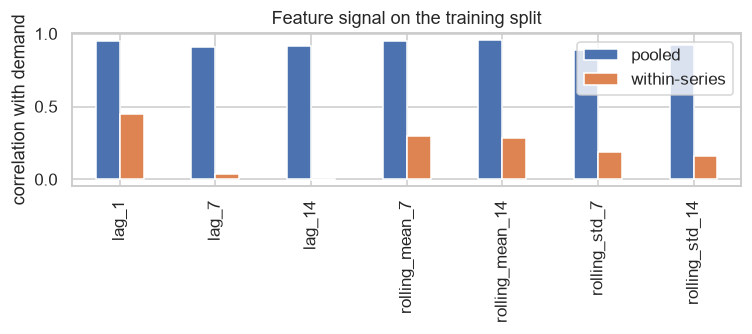

In [4]:
# Correlation of each feature with demand on eligible training rows. Each series is demeaned first so that the
# comparison reflects day-to-day information, not the level differences between series.
train = data[(data.split == "train") & data.history_ready & data.city_observed].copy()
cols = ["demand", "lag_1", "lag_7", "lag_14", "rolling_mean_7", "rolling_mean_14", "rolling_std_7", "rolling_std_14"]
within = train[cols] - train.groupby("series_id")[cols].transform("mean")
signal = pd.DataFrame({"pooled": train[cols].corr()["demand"], "within-series": within.corr()["demand"]}).drop("demand").round(3)
display(signal)
print("eligible training rows:", len(train), "| series:", train.series_id.nunique())
fig, ax = plt.subplots(figsize=(7, 3.2))
signal.plot.bar(ax=ax); ax.set_ylabel("correlation with demand"); ax.set_title("Feature signal on the training split")
saveFigure("feature_signal_train")

## 4. Kết luận

## Kết luận

**Cấu trúc đặc trưng.** Với mỗi chuỗi `region_id × aoi_type`, đặc trưng của ngày t gồm lag 1, 7, 14, trung bình trượt và độ lệch chuẩn trượt 7 và 14 ngày (dịch một ngày trước khi tính) cùng ngày trong tháng và tháng. Bảng đặc trưng của cửa sổ chính có 4.018 dòng (41 chuỗi × 98 ngày); 14 ngày đầu là giai đoạn khởi động, ngày đầu tiên có đủ lịch sử là 11/7.

**Chia dữ liệu.** Huấn luyện 27/6–23/8 (44 ngày đủ lịch sử, 1.804 dòng, 10.835 đơn), kiểm định 24/8–12/9 (20 ngày, 820 dòng, 5.300 đơn), kiểm tra 13/9–2/10 (20 ngày, 820 dòng, 4.732 đơn). Cửa sổ chính không chứa ngày không quan sát nào.

**Kiểm tra rò rỉ.** Cả bốn kiểm tra đều đạt: (a) đổi giá trị mục tiêu từ 30/8 trở đi không làm đổi đặc trưng của các ngày đến 30/8; (b) `rolling_mean_14` và `lag_7` chỉ dùng dữ liệu trước ngày t; (c) ngày không quan sát luôn là NaN, và `lag_1` của ngày liền sau là NaN; (d) bảng đặc trưng đã lưu khớp bảng dựng lại.

**Tín hiệu đặc trưng.** Tương quan gộp với mục tiêu rất cao (0,89–0,96) nhưng chủ yếu do chênh lệch mức giữa các chuỗi. Sau khi trừ trung bình từng chuỗi, tương quan là 0,45 với `lag_1`, 0,30 với `rolling_mean_7`, 0,28 với `rolling_mean_14`, 0,04 với `lag_7` và 0,00 với `lag_14`. Tương quan ở lag 7 yếu trong EDA; điều này chưa đủ để kết luận nhóm đặc trưng thứ trong tuần không hữu ích. Đặc trưng này được giữ làm ứng viên và đánh giá bằng mô hình và ablation ở RQ2.

**Phạm vi.** Notebook này chỉ dựng và kiểm tra đặc trưng; các mô hình dự báo (baseline) được đánh giá trong `03_forecasting`.